# 2. Observed transmission loss and celerity

A 2×2 comparison in the layout of manuscript Figure 3: **columns = WNW and South**, **rows = transmission loss and celerity**, **10–12 Hz**. Read the ten copied metric files and local AWS data. Uses exactly the requested receivers; unlike the original Figure 3 notebook, **S068b is not merged into S068a** because it was not part of the requested export.

## Imports and settings

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import utils
ROOT = Path(utils.__file__).resolve().parent
assert Path.cwd().resolve() == ROOT, 'Start Jupyter from the example folder.'

from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from utils import (GROUPS, START, END, TZ, get_aws, get_c_ad, get_c_eff, load_metrics,
    station_geometry, circular_mean, local_time, time_axes)
FL, FH = 10.0, 12.0
MIN_INTERVALS, SNR_THRESHOLD = 20, 3.0

## Load the copied observations
Apply the existing station-time exclusions, select the 10–12 Hz band and require at least 20 chirps in each stacked response. SNR < 3 will be shown in grey rather than removed.

In [2]:
geometry = station_geometry()
observations = {}
for group, receivers in GROUPS.items():
    observations[group] = {}
    for receiver in receivers:
        frame = load_metrics(receiver, START, END, FL, FH)
        frame = frame[frame.n_intvs >= MIN_INTERVALS].copy()
        observations[group][receiver] = frame
    print(group, {r:len(d) for r,d in observations[group].items()})
reference = load_metrics('S007a', START, END, FL, FH)
assert len(reference) > 0
print('Reference rows:',len(reference))

WNW {'S084a': 1135, 'S074a': 1135, 'S096a': 1135, 'S092a': 1135}
South {'S068a': 920, 'S094a': 1135, 'S020a': 1135, 'S019a': 1135, 'S076a': 1135}
Reference rows: 1145


## Compute AWS surface sound speeds
**Ground effective sound speed** includes the wind component along the group mean propagation azimuth. Manuscript Figure 3 uses **adiabatic sound speed**, which depends on temperature alone. Both are plotted and labelled separately; the gradient inversion in Notebook 3 retains the manuscript's adiabatic surface-speed assumption.

In [3]:
aws = get_aws(START, END)
aws['c_ad'] = get_c_ad(aws.T_K.to_numpy())
aws['time_local'] = local_time(aws.time)
mean_azimuth = {g:circular_mean(geometry.loc[receivers,'az']) for g,receivers in GROUPS.items()}
for group, az in mean_azimuth.items():
    aws[f'c_eff_{group}'] = get_c_eff(aws.T_K.to_numpy(),aws.u_ms.to_numpy(),aws.v_ms.to_numpy(),az)
print('Group mean azimuths:',mean_azimuth)

Group mean azimuths: {'WNW': 285.49452706024726, 'South': 180.62500846703944}


## Plot the 2×2 observations figure
Receiver colours share one distance scale. Small horizontal bars show spherical-spreading TL relative to S007a. Vertical dashed lines indicate eclipse totality, sunset and thunderstorm onset. The x-axis is Dallas local time (CDT).

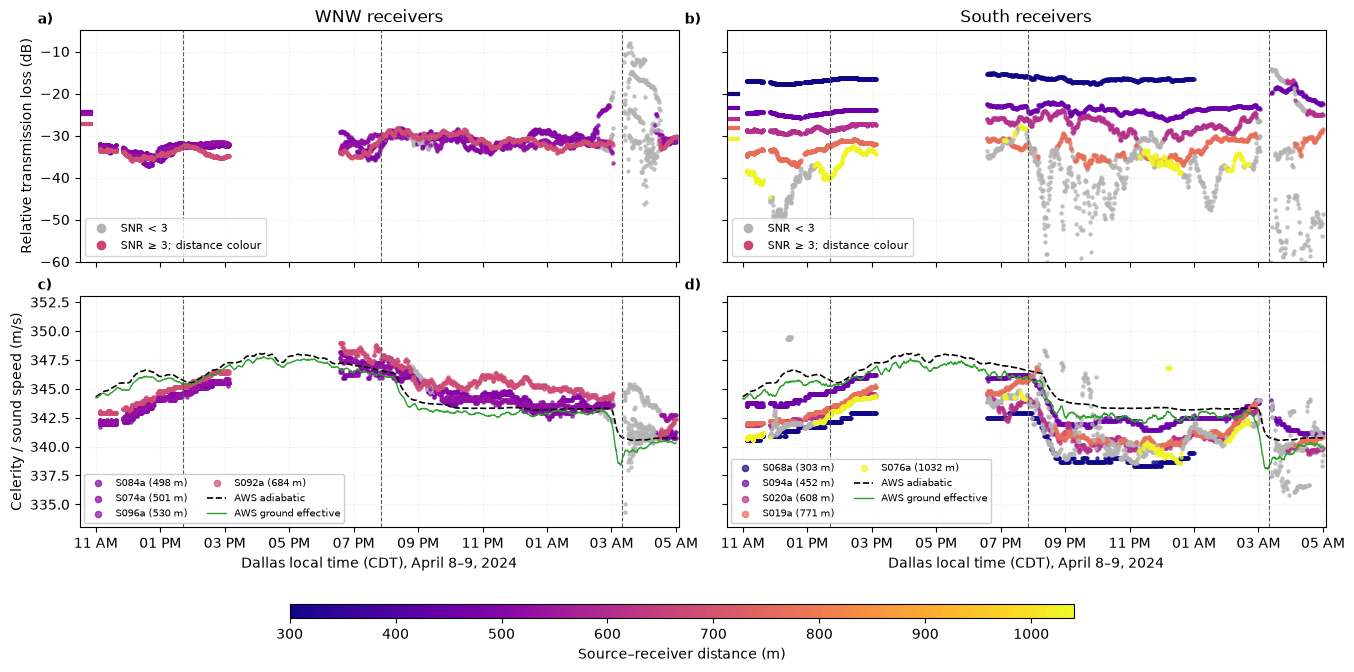

In [4]:
fig, axes = plt.subplots(2,2,figsize=(14,7),sharex=True,sharey='row')
fig.subplots_adjust(left=0.07,right=0.96,bottom=0.20,top=0.91,hspace=0.15,wspace=0.08)
norm, cmap = Normalize(300,1040), plt.get_cmap('plasma')
for col,(group,receivers) in enumerate(GROUPS.items()):
    ax_tl, ax_c = axes[:,col]
    for receiver in sorted(receivers,key=lambda r:geometry.loc[r,'dist']):
        d = observations[group][receiver]
        distance=float(geometry.loc[receiver,'dist'])
        colour=cmap(norm(distance))
        valid=d.amp_snr >= SNR_THRESHOLD
        for mask,colour_plot in [(~valid,'0.7'),(valid,colour)]:
            ax_tl.scatter(local_time(d.loc[mask,'evt0']),d.loc[mask,'tl'],s=5,color=colour_plot,alpha=0.7)
            ax_c.scatter(local_time(d.loc[mask,'evt0']),d.loc[mask,'c_est'],s=5,color=colour_plot,alpha=0.7,
                         label=f'{receiver} ({distance:.0f} m)' if mask is valid else None)
        ref_distance=float(d.dist_ref.median())
        tl_spherical=-20*np.log10(distance/ref_distance)
        ax_tl.plot([local_time(START)-pd.Timedelta(minutes=27),local_time(START)-pd.Timedelta(minutes=9)],
                   [tl_spherical]*2,color=colour,lw=3)
    ax_c.plot(aws.time_local,aws.c_ad,'k--',lw=1.2,label='AWS adiabatic')
    ax_c.plot(aws.time_local,aws[f'c_eff_{group}'],color='tab:green',lw=1.0,label='AWS ground effective')
    ax_tl.set_title(group+' receivers')
    ax_tl.set_ylim(-60,-5); ax_c.set_ylim(333,353)
    ax_c.legend(loc='lower left',fontsize=7,ncol=2,markerscale=2,framealpha=0.95)
    ax_tl.legend(handles=[Line2D([],[],marker='o',ls='',color='0.7',label='SNR < 3'),
                         Line2D([],[],marker='o',ls='',color=cmap(0.5),label='SNR ≥ 3; distance colour')],fontsize=8,loc='lower left')
    ax_c.set_xlabel('Dallas local time (CDT), April 8–9, 2024')
axes[0,0].set_ylabel('Relative transmission loss (dB)')
axes[1,0].set_ylabel('Celerity / sound speed (m/s)')
time_axes(axes)
for ax,label in zip(axes.flat,'abcd'):
    ax.text(-0.07,1.03,label+')',transform=ax.transAxes,fontweight='bold')
cax=fig.add_axes([0.22,0.07,0.56,0.02])
fig.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=cmap),cax=cax,orientation='horizontal',label='Source–receiver distance (m)')
plt.show()